# **Deep Learning Project**

In [ ]:
!PYTHONHASHSEED=0

In [ ]:
import tensorflow as tf
from tensorflow import keras
from matplotlib import pyplot as plt
import zipfile
from shutil import copyfile
from time import time
import numpy as np
import random as python_random
import os
from glob import glob
import pandas as pd
import seaborn as sns
from PIL import Image

In [ ]:
np.random.seed(0)
python_random.seed(0)
tf.random.set_seed(0)

## Dataset Download

In [ ]:
dataset_url = "http://download.tensorflow.org/example_images/flower_photos.tgz"
base_dir = tf.keras.utils.get_file(origin=dataset_url,
                                    fname='flower_photos',
                                    untar=True)

if os.path.isdir(os.path.join(base_dir, 'flower_photos')):
    data_dir = os.path.join(base_dir, 'flower_photos')
else:
    data_dir = base_dir

print(f"Dataset downloaded and extracted to: {data_dir}")
print(f"Classes: {os.listdir(data_dir)}")

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset downloaded and extracted to: /root/.keras/datasets/flower_photos/flower_photos
Classes: ['dandelion', 'sunflowers', 'daisy', 'LICENSE.txt', 'roses', 'tulips']


In [ ]:
num_classes = 5

## Data Exploration

In [ ]:
class_names = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)) and d != 'LICENSE.txt']
class_names.sort()

image_counts = {}
for class_name in class_names:
    class_path = os.path.join(data_dir, class_name)
    images = glob(os.path.join(class_path, '*.jpg'))
    image_counts[class_name] = len(images)

print("Class Names:", class_names)
print("Image Counts per Class:", image_counts)

Class Names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Image Counts per Class: {'daisy': 633, 'dandelion': 898, 'roses': 641, 'sunflowers': 699, 'tulips': 799}


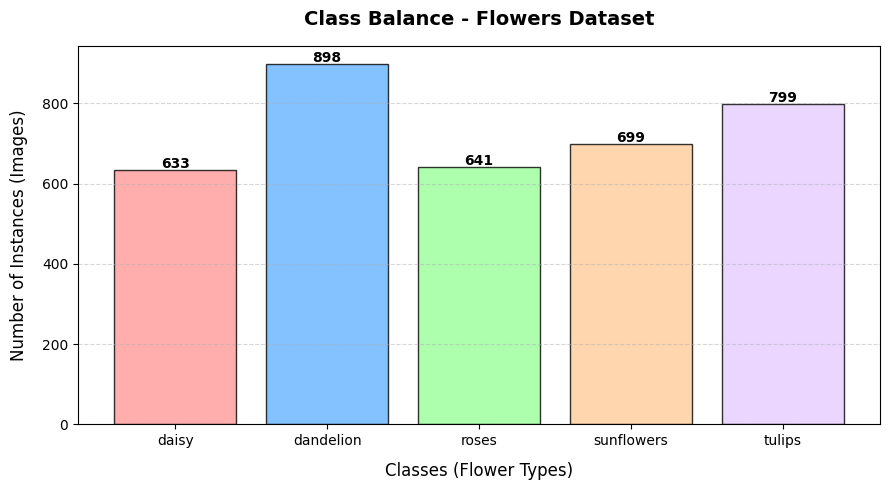

In [ ]:
plt.figure(figsize=(9, 5))

flower_colors = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#E5CCFF']

plt.bar(image_counts.keys(), image_counts.values(), color=flower_colors, edgecolor='black', alpha=0.8)

plt.title("Class Balance - Flowers Dataset", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Classes (Flower Types)", fontsize=12, labelpad=10)
plt.ylabel("Number of Instances (Images)", fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, (class_name, count) in enumerate(image_counts.items()):
    plt.text(i, count + 5, str(count), ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
image_widths = []
image_heights = []
image_formats = set()

all_image_paths = []
for class_name in class_names:
    class_path = os.path.join(data_dir, class_name)
    all_image_paths.extend(glob(os.path.join(class_path, '*.jpg')))

sample_size = min(len(all_image_paths), 3670)
sampled_image_paths = np.random.choice(all_image_paths, sample_size, replace=False)

for img_path in sampled_image_paths:
    try:
        with Image.open(img_path) as img:
            image_widths.append(img.width)
            image_heights.append(img.height)
            image_formats.add(img.format)
    except Exception as e:
        print(f"Could not process image {img_path}: {e}")

print(f"\nTotal images analyzed: {len(image_widths)}")
print(f"Unique Image Formats: {image_formats}")
print(f"Average Image Width: {np.mean(image_widths):.2f} pixels")
print(f"Average Image Height: {np.mean(image_heights):.2f} pixels")
print(f"Min Image Width: {np.min(image_widths)} pixels")
print(f"Max Image Width: {np.max(image_widths)} pixels")
print(f"Min Image Height: {np.min(image_heights)} pixels")
print(f"Max Image Height: {np.max(image_heights)} pixels")


Total images analyzed: 3670
Unique Image Formats: {'JPEG'}
Average Image Width: 365.06 pixels
Average Image Height: 271.79 pixels
Min Image Width: 143 pixels
Max Image Width: 1024 pixels
Min Image Height: 159 pixels
Max Image Height: 442 pixels


In [ ]:
aspect_ratios = []

for i in range(len(image_widths)): # Using the lists from the previous cell
    if image_heights[i] > 0:
        aspect_ratios.append(image_widths[i] / image_heights[i])

print(f"\nAverage Aspect Ratio: {np.mean(aspect_ratios):.2f}")
print(f"Min Aspect Ratio: {np.min(aspect_ratios):.2f}")
print(f"Max Aspect Ratio: {np.max(aspect_ratios):.2f}")


Average Aspect Ratio: 1.33
Min Aspect Ratio: 0.60
Max Aspect Ratio: 5.48


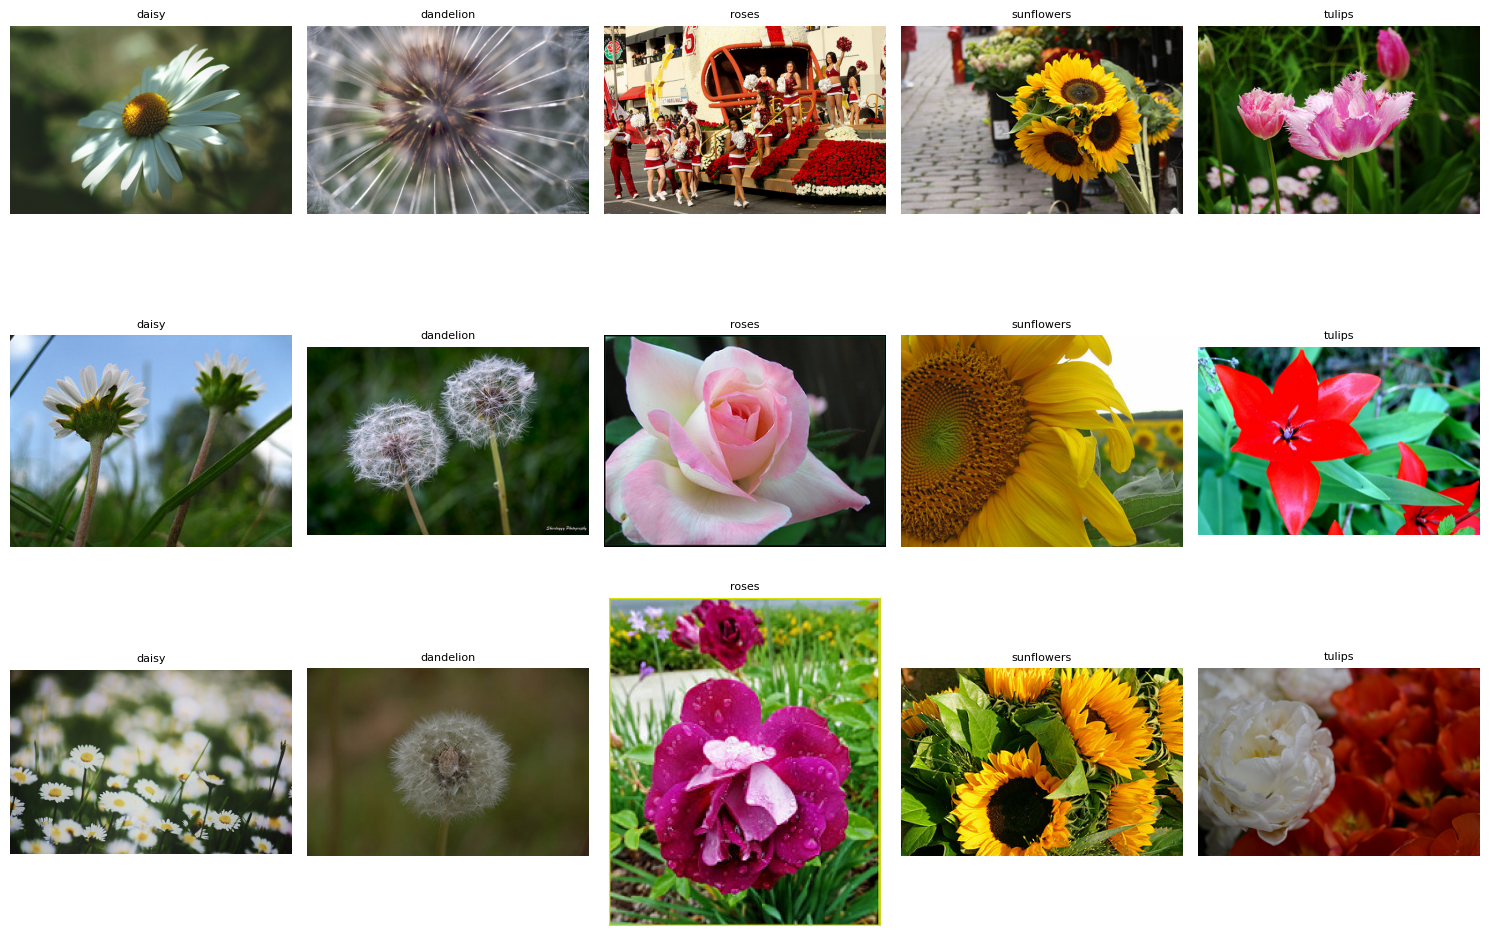

In [ ]:
plt.figure(figsize=(15, 10))

num_samples_per_class = 3

for i, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    images_in_class = glob(os.path.join(class_path, '*.jpg'))

    sampled_images = np.random.choice(images_in_class, min(num_samples_per_class, len(images_in_class)), replace=False)

    for j, img_path in enumerate(sampled_images):
        plt.subplot(num_samples_per_class, num_classes, j * num_classes + i + 1)
        try:
            img = Image.open(img_path)
            plt.imshow(img)
            plt.title(f"{class_name}", fontsize=8)
            plt.axis('off')
        except Exception as e:
            print(f"Could not load sample image {img_path}: {e}")
            plt.text(0.5, 0.5, 'Error', ha='center', va='center')
            plt.axis('off')

plt.tight_layout()
plt.show()

## Training and validation set

In [ ]:
train_dataset = keras.utils.image_dataset_from_directory(data_dir,
                                                            image_size=(224,224),
                                                            batch_size=32,
                                                            label_mode='categorical',
                                                            subset='training',
                                                            validation_split = 0.2,
                                                            shuffle=True,
                                                            seed=1)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [ ]:
val_dataset = keras.utils.image_dataset_from_directory(data_dir,
                                                            image_size=(224,224),
                                                            batch_size=32,
                                                            label_mode='categorical',
                                                            subset='validation',
                                                            validation_split = 0.2,
                                                            shuffle=True,
                                                            seed=1)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


## Model Training

In [ ]:
from IPython.display import Javascript
def resize_colab_cell():
  display(Javascript('google.colab.output.setIframeHeight(0, true, {maxHeight: 500})'))
get_ipython().events.register('pre_run_cell', resize_colab_cell)

**1) BASE MODEL**

In [ ]:
inputs = keras.Input((224,224,3))

x = inputs
x = keras.layers.Rescaling(1./255)(x)

x = keras.layers.Conv2D(32, 3, padding="same")(x)
x = keras.layers.Activation("relu")(x)

x = keras.layers.GlobalMaxPooling2D()(x)
outputs = keras.layers.Dense(num_classes, activation="softmax")(x)

net = keras.Model(inputs, outputs)

<IPython.core.display.Javascript object>

In [ ]:
net.compile(loss=keras.losses.categorical_crossentropy,
            optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
            metrics=['accuracy'])

<IPython.core.display.Javascript object>

In [ ]:
history1 = net.fit(train_dataset,
          epochs=40,
          validation_data=val_dataset);

<IPython.core.display.Javascript object>

Epoch 1/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 84ms/step - accuracy: 0.2810 - loss: 1.5864 - val_accuracy: 0.3488 - val_loss: 1.5403
Epoch 2/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - accuracy: 0.4159 - loss: 1.4873 - val_accuracy: 0.4973 - val_loss: 1.4225
Epoch 3/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.4935 - loss: 1.3599 - val_accuracy: 0.5613 - val_loss: 1.2687
Epoch 4/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.5412 - loss: 1.2348 - val_accuracy: 0.6022 - val_loss: 1.1660
Epoch 5/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.5712 - loss: 1.1473 - val_accuracy: 0.6471 - val_loss: 1.0992
Epoch 6/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.5950 - loss: 1.0872 - val_accuracy: 0.6458 - val_loss: 1.0595
Epoch 7/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.6056 - loss: 1.0449 - val_accuracy: 0.6376 - val_loss: 1.0323
Epoch 8/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.6175 - loss: 1.0118 - val_accuracy: 0.6471 -

<IPython.core.display.Javascript object>

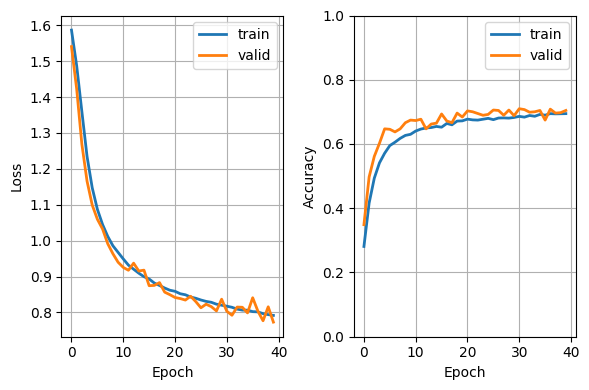

In [ ]:
plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
plt.plot(history1.history['loss'], label='train', linewidth=2)
plt.plot(history1.history['val_loss'], label='valid', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history1.history['accuracy'], label='train', linewidth=2)
plt.plot(history1.history['val_accuracy'], label='valid', linewidth=2)
plt.ylim([0.0, 1.0])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
net.save('model1.keras')

<IPython.core.display.Javascript object>

**2) DEEPER ARCHITECTURE**


In [ ]:
inputs = keras.Input(shape=(224, 224, 3))

x = inputs
x = keras.layers.Rescaling(1./255)(x)

x = keras.layers.Conv2D(32, 3, padding="same")(x)
x = keras.layers.Activation("relu")(x)
x = keras.layers.MaxPooling2D(3, strides=3, padding="same")(x)

x = keras.layers.Conv2D(64, 3, padding="same")(x)
x = keras.layers.Activation("relu")(x)
x = keras.layers.MaxPooling2D(3, strides=3, padding="same")(x)

x = keras.layers.Conv2D(128, 3, padding="same")(x)
x = keras.layers.Activation("relu")(x)

x = keras.layers.GlobalMaxPooling2D()(x)
outputs = keras.layers.Dense(num_classes, activation="softmax")(x)

net = keras.Model(inputs, outputs)

<IPython.core.display.Javascript object>

In [ ]:
net.compile(loss=keras.losses.categorical_crossentropy,
            optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
            metrics=['accuracy'])

<IPython.core.display.Javascript object>

In [ ]:
history2 = net.fit(train_dataset,
          epochs=40,
          validation_data=val_dataset);

<IPython.core.display.Javascript object>

Epoch 1/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - accuracy: 0.4605 - loss: 1.2975 - val_accuracy: 0.6199 - val_loss: 1.0584
Epoch 2/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.5746 - loss: 1.0516 - val_accuracy: 0.6022 - val_loss: 0.9995
Epoch 3/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6332 - loss: 0.9329 - val_accuracy: 0.6458 - val_loss: 0.8939
Epoch 4/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.6662 - loss: 0.8499 - val_accuracy: 0.5245 - val_loss: 1.1452
Epoch 5/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.6972 - loss: 0.7954 - val_accuracy: 0.7221 - val_loss: 0.7398
Epoch 6/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.7204 - loss: 0.7367 - val_accuracy: 0.7221 - val_loss: 0.7253
Epoch 7/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.7449 - loss: 0.6855 - val_accuracy: 0.7153 - val_loss: 0.7662
Epoch 8/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.7653 - loss: 0.6386 - val_accuracy: 0.7084

<IPython.core.display.Javascript object>

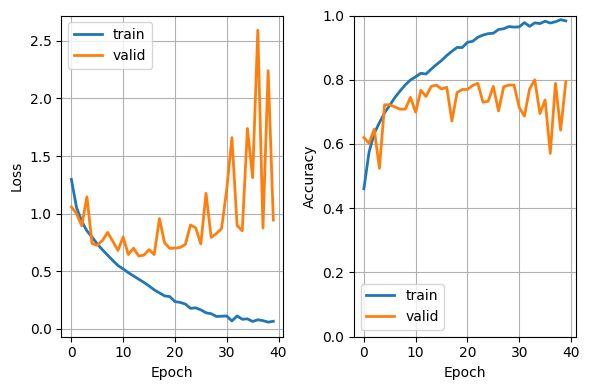

In [ ]:
plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
plt.plot(history2.history['loss'], label='train', linewidth=2)
plt.plot(history2.history['val_loss'], label='valid', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history2.history['accuracy'], label='train', linewidth=2)
plt.plot(history2.history['val_accuracy'], label='valid', linewidth=2)
plt.ylim([0.0, 1.0])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
net.save('model2.keras')

<IPython.core.display.Javascript object>

**3) BATCH NORMALIZATION AND EARLY STOPPING**

In [ ]:
inputs = keras.Input(shape=(224, 224, 3))

x = inputs
x = keras.layers.Rescaling(1./255)(x)

x = keras.layers.Conv2D(32, 3, padding="same", kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Activation("relu")(x)
x = keras.layers.MaxPooling2D(3, strides=3, padding="same")(x)

x = keras.layers.Conv2D(64, 3, padding="same", kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Activation("relu")(x)
x = keras.layers.MaxPooling2D(3, strides=3, padding="same")(x)

x = keras.layers.Conv2D(128, 3, padding="same", kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Activation("relu")(x)

x = keras.layers.GlobalMaxPooling2D()(x)
x = keras.layers.Dense(64, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
outputs = keras.layers.Dense(num_classes, activation="softmax", kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)

net = keras.Model(inputs, outputs)

<IPython.core.display.Javascript object>

In [ ]:
net.compile(loss=keras.losses.categorical_crossentropy,
            optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
            metrics=['accuracy'])

<IPython.core.display.Javascript object>

In [ ]:
callback_es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

<IPython.core.display.Javascript object>

In [ ]:
history3 = net.fit(train_dataset,
                  epochs=100,
                  validation_data=val_dataset,
                  callbacks=[callback_es])

<IPython.core.display.Javascript object>

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 135ms/step - accuracy: 0.5688 - loss: 1.3565 - val_accuracy: 0.2684 - val_loss: 1.9620
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.6747 - loss: 1.0439 - val_accuracy: 0.3270 - val_loss: 2.0972
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.7173 - loss: 0.9198 - val_accuracy: 0.4183 - val_loss: 1.7730
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.7701 - loss: 0.8216 - val_accuracy: 0.5368 - val_loss: 1.4207
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.7711 - loss: 0.7756 - val_accuracy: 0.6567 - val_loss: 1.0755
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.8062 - loss: 0.7009 - val_accuracy: 0.6962 - val_loss: 0.9898
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - accuracy: 0.8338 - loss: 0.6280 - val_accuracy: 0.7452 - val_loss: 0.8321
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.8539 - loss: 0.5774 - val_accuracy

<IPython.core.display.Javascript object>

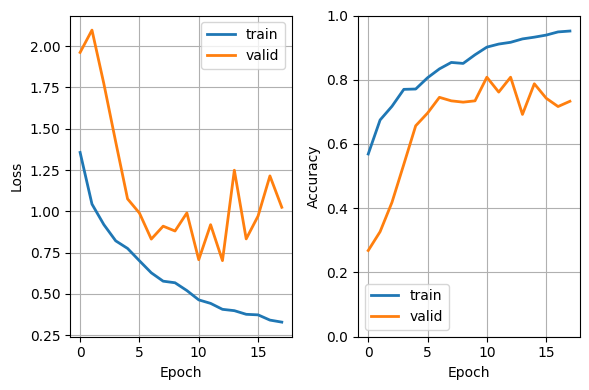

In [ ]:
plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
plt.plot(history3.history['loss'], label='train', linewidth=2)
plt.plot(history3.history['val_loss'], label='valid', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history3.history['accuracy'], label='train', linewidth=2)
plt.plot(history3.history['val_accuracy'], label='valid', linewidth=2)
plt.ylim([0.0, 1.0])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
net.save('model3.keras')

<IPython.core.display.Javascript object>

**4) DATA AUGMENTATION**

In [ ]:
train_dataset_256 = keras.utils.image_dataset_from_directory(data_dir,
                                                            image_size=(256,256),
                                                            batch_size=32,
                                                            label_mode='categorical',
                                                            subset='training',
                                                            validation_split = 0.2,
                                                            shuffle=True,
                                                            seed=1)

<IPython.core.display.Javascript object>

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [ ]:
inputs = keras.Input((None,None,3))

x = inputs
x = keras.layers.Rescaling(1./255)(x)

x = keras.layers.RandomCrop(224, 224)(x)
x = keras.layers.RandomFlip(mode='horizontal')(x)
x = keras.layers.RandomContrast(0.25)(x)

x = keras.layers.Conv2D(32, 3, padding="same", kernel_regularizer='l2')(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Activation("relu")(x)
x = keras.layers.MaxPooling2D(3, strides=3, padding="same")(x)

x = keras.layers.Conv2D(64, 3, padding="same", kernel_regularizer='l2')(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Activation("relu")(x)
x = keras.layers.MaxPooling2D(3, strides=3, padding="same")(x)

x = keras.layers.Conv2D(128, 3, padding="same", kernel_regularizer='l2')(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Activation("relu")(x)

x = keras.layers.GlobalMaxPooling2D()(x)
x = keras.layers.Dense(64, activation="relu", kernel_regularizer='l2')(x)
outputs = keras.layers.Dense(num_classes, activation="softmax")(x)

net = keras.Model(inputs, outputs)

<IPython.core.display.Javascript object>

In [ ]:
net.compile(loss=keras.losses.categorical_crossentropy,
            optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
            metrics=['accuracy'])

<IPython.core.display.Javascript object>

In [ ]:
callback_es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

<IPython.core.display.Javascript object>

In [ ]:
history4 = net.fit(train_dataset_256,
                  epochs=100,
                  validation_data=val_dataset,
                  callbacks=[callback_es])

<IPython.core.display.Javascript object>

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 119ms/step - accuracy: 0.5484 - loss: 3.0974 - val_accuracy: 0.2820 - val_loss: 3.1678
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - accuracy: 0.6574 - loss: 2.1995 - val_accuracy: 0.2684 - val_loss: 3.1928
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - accuracy: 0.7003 - loss: 1.7615 - val_accuracy: 0.2698 - val_loss: 3.1581
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - accuracy: 0.7323 - loss: 1.5090 - val_accuracy: 0.3256 - val_loss: 2.3579
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.7381 - loss: 1.3540 - val_accuracy: 0.5518 - val_loss: 1.7445
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - accuracy: 0.7520 - loss: 1.2744 - val_accuracy: 0.6335 - val_loss: 1.5031
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.7616 - loss: 1.1751 - val_accuracy: 0.7248 - val_loss: 1.2562
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 111ms/step - accuracy: 0.7735 - loss: 1.1039 - 

<IPython.core.display.Javascript object>

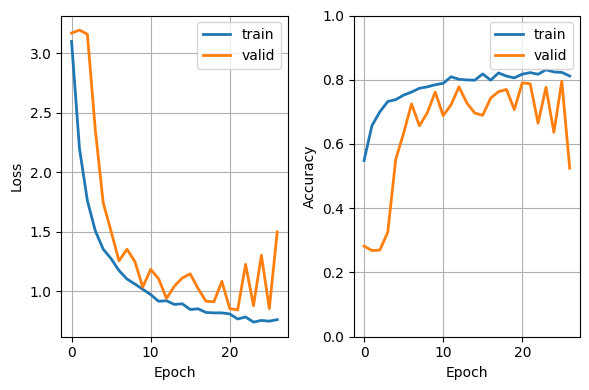

In [ ]:
plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
plt.plot(history4.history['loss'], label='train', linewidth=2)
plt.plot(history4.history['val_loss'], label='valid', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history4.history['accuracy'], label='train', linewidth=2)
plt.plot(history4.history['val_accuracy'], label='valid', linewidth=2)
plt.ylim([0.0, 1.0])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
net.save('model4.keras')

<IPython.core.display.Javascript object>

**5) TRANSFER LEARNING**

In [ ]:
base_net = keras.applications.MobileNetV2(input_shape=(224, 224, 3),
                                          include_top=False,
                                          weights='imagenet',
                                          pooling = 'avg')
base_net.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_net(x)
x = keras.layers.Dense(1024, activation='relu')(x)
outputs = keras.layers.Dense(5, activation='softmax')(x)

net = keras.Model(inputs, outputs)

<IPython.core.display.Javascript object>

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
net.compile(loss=keras.losses.categorical_crossentropy,
            optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
            metrics=['accuracy'])

<IPython.core.display.Javascript object>

In [ ]:
callback_es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

<IPython.core.display.Javascript object>

In [ ]:
history5 = net.fit(train_dataset,
          epochs=10,
          validation_data=val_dataset,
          callbacks=[callback_es]);

<IPython.core.display.Javascript object>

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 64s 436ms/step - accuracy: 0.7861 - loss: 0.7314 - val_accuracy: 0.8460 - val_loss: 0.4304
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 82ms/step - accuracy: 0.8985 - loss: 0.2674 - val_accuracy: 0.7888 - val_loss: 0.6753
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.9435 - loss: 0.1723 - val_accuracy: 0.9101 - val_loss: 0.2972
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.9636 - loss: 0.1009 - val_accuracy: 0.9196 - val_loss: 0.3123
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 82ms/step - accuracy: 0.9806 - loss: 0.0591 - val_accuracy: 0.9101 - val_loss: 0.3478
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.9826 - loss: 0.0434 - val_accuracy: 0.9033 - val_loss: 0.4196
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9911 - loss: 0.0292 - val_accuracy: 0.9183 - val_loss: 0.4254
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - accuracy: 0.9956 - loss: 0.0138 - val_accuracy: 0.9087

<IPython.core.display.Javascript object>

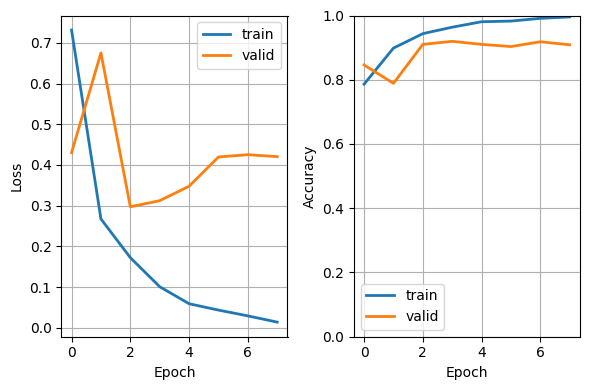

In [ ]:
plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
plt.plot(history5.history['loss'], label='train', linewidth=2)
plt.plot(history5.history['val_loss'], label='valid', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history5.history['accuracy'], label='train', linewidth=2)
plt.plot(history5.history['val_accuracy'], label='valid', linewidth=2)
plt.ylim([0.0, 1.0])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
net.save('model5.keras')

<IPython.core.display.Javascript object>